In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import os
import time
import cv2
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from keras.models import Sequential
from keras.layers import Input, Dense, Conv2D, MaxPooling2D, Dropout, Flatten, BatchNormalization
from keras import callbacks, regularizers
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sn



In [2]:
path_train = "../Data/dataset_yawn_eye/train"
path_test = "../Data/dataset_yawn_eye/test/"
path_haar_faces = "../Data/dataset_yawn_eye/haarcascade/haarcascade_frontalface_default.xml"

labels = os.listdir(path_train)
labels.remove(".DS_Store")
labels.remove("no_yawn")
labels.remove("yawn")
labels

IMG_SIZE = (145, 145)


In [26]:
labels

['Closed', 'Open']

### Import and resize image-data

In [3]:

def load_data(path_data):
    X = []
    y = []

    for label in os.listdir(path_data):
        if label in labels:
            path = os.path.join(path_data, label)
            label_index = labels.index(label)
            print(label)

            for file in os.listdir(path):
                if not file.startswith('.'):
                    img_matrix = cv2.imread(os.path.join(path, file), cv2.IMREAD_GRAYSCALE)
                    
                    try:
                        img_final = cv2.resize(img_matrix, IMG_SIZE)

                        X.append(img_final)
                        y.append(label_index)

                    except Exception as e:
                        print(e)
    return X, y



In [4]:
x_train, y_train = load_data(path_train)
x_test, y_test = load_data(path_test)


print("x_train len: ", len(x_train))
print("y_train len: ", len(y_train))
print(f'labels : {list(set(y_train))}')
print(f'x_train-shape: ({ len(x_train) }, { len(x_train[0]) }, { len(x_train[0][0]) })')

print("Testdaten:")
print("x_train len: ", len(x_train))
print("y_train len: ", len(y_train))
print(f'labels : {list(set(y_train))}')
print(f'x_train-shape: ({ len(x_train) }, { len(x_train[0]) }, { len(x_train[0][0]) })')

Closed
Open
Closed
Open
x_train len:  1234
y_train len:  1234
labels : [0, 1]
x_train-shape: (1234, 145, 145)
Testdaten:
x_train len:  1234
y_train len:  1234
labels : [0, 1]
x_train-shape: (1234, 145, 145)


#### Save image-data to binary files

In [5]:
npx = np.array(x_train)
dfx = pd.DataFrame(npx.reshape((npx.shape[0], npx.shape[1] * npx.shape[2])))

npy = np.array(y_train)
dfy = pd.DataFrame(npy)

dfx.to_csv("../Data/dataset_yawn_eye/preprocessed/x_train_eye.csv")
dfy.to_csv("../Data/dataset_yawn_eye/preprocessed/y_train_eye.csv")

npx = np.array(x_test)
dfx = pd.DataFrame(npx.reshape((npx.shape[0], npx.shape[1] * npx.shape[2])))

npy = np.array(y_test)
dfy = pd.DataFrame(npy)

dfx.to_csv("../Data/dataset_yawn_eye/preprocessed/x_test_eye.csv")
dfy.to_csv("../Data/dataset_yawn_eye/preprocessed/y_test_eye.csv")

### Read preprocessed CSV-data

In [6]:

def read_all_csv_data():
    path_x_csv = "../Data/dataset_yawn_eye/preprocessed/x_train_eye.csv"
    path_y_csv = "../Data/dataset_yawn_eye/preprocessed/y_train_eye.csv"
    path_x_csv_test = "../Data/dataset_yawn_eye/preprocessed/x_test_eye.csv"
    path_y_csv_test = "../Data/dataset_yawn_eye/preprocessed/y_test_eye.csv"

    x_read = pd.read_csv(path_x_csv, index_col = 0)
    y_read = pd.read_csv(path_y_csv, index_col = 0)
    x_read_test = pd.read_csv(path_x_csv_test, index_col = 0)
    y_read_test = pd.read_csv(path_y_csv_test, index_col = 0)

    x_train = x_read.values.reshape((len(x_read.index), IMG_SIZE[0], IMG_SIZE[1]))
    y_train = np.array(y_read).reshape(np.array(y_read).shape[0]).tolist()

    x_test = x_read.values.reshape((len(x_read.index), IMG_SIZE[0], IMG_SIZE[1]))
    y_test = np.array(y_read).reshape(np.array(y_read).shape[0]).tolist()

    del x_read
    del y_read
    del x_read_test
    del y_read_test

    return x_train, x_test, y_train, y_test

x_train, x_test, y_train, y_test = read_all_csv_data()

In [7]:
# normalize data
x_train = x_train.reshape((x_train.shape[0], x_train.shape[1] * x_train.shape[2]))
x_train = x_train.astype(float) / 255
x_test = x_test.reshape((x_test.shape[0], x_test.shape[1] * x_test.shape[2]))
x_test = x_test.astype(float) / 255

encoder = LabelEncoder()
y_train = encoder.fit_transform(y_train)
y_test = encoder.fit_transform(y_test)

### Create and train simple MLP model

In [8]:
model_mlp = Sequential()
model_mlp.add(Input(shape=(IMG_SIZE[0] * IMG_SIZE[1],)))
model_mlp.add(Dense(256, activation="relu"))
model_mlp.add(Dense(128, activation="relu"))
model_mlp.add(Dense(len(set(y_train)), activation="softmax"))

model_mlp.summary()

model_mlp.compile(
    optimizer = "adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False), 
    metrics=[tf.keras.metrics.SparseCategoricalAccuracy()]
)

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 256)               5382656   
                                                                 
 dense_1 (Dense)             (None, 128)               32896     
                                                                 
 dense_2 (Dense)             (None, 2)                 258       
                                                                 
Total params: 5415810 (20.66 MB)
Trainable params: 5415810 (20.66 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [9]:
# early stopping callback

early_stopping = callbacks.EarlyStopping(
    monitor = "test_accuracy",
    mode = "max",
    min_delta = 0.03,
    patience = 2,
    restore_best_weights = True
)

In [10]:
# training of MLP
timer_start = time.time()

history = model_mlp.fit(
    x = x_train,
    y = y_train,
    validation_data = (x_test, y_test),
    # callbacks = [early_stopping],
    epochs = 50
)

timer_end = time.time()

print('\nGesamtlaufzeit: {:5.2f}s'.format(timer_end - timer_start))

Epoch 1/50
39/39 [==============================] - 1s 17ms/step - loss: 1.9519 - sparse_categorical_accuracy: 0.7050 - val_loss: 0.4751 - val_sparse_categorical_accuracy: 0.7853
Epoch 2/50
39/39 [==============================] - 0s 12ms/step - loss: 0.4063 - sparse_categorical_accuracy: 0.8395 - val_loss: 0.2660 - val_sparse_categorical_accuracy: 0.9149
Epoch 3/50
39/39 [==============================] - 1s 13ms/step - loss: 0.7487 - sparse_categorical_accuracy: 0.7650 - val_loss: 0.9863 - val_sparse_categorical_accuracy: 0.6937
Epoch 4/50
39/39 [==============================] - 0s 10ms/step - loss: 0.4242 - sparse_categorical_accuracy: 0.8549 - val_loss: 0.3827 - val_sparse_categorical_accuracy: 0.8679
Epoch 5/50
39/39 [==============================] - 0s 11ms/step - loss: 0.2714 - sparse_categorical_accuracy: 0.9076 - val_loss: 0.2361 - val_sparse_categorical_accuracy: 0.9222
Epoch 6/50
39/39 [==============================] - 0s 11ms/step - loss: 0.2578 - sparse_categorical_accu

In [11]:
predictions = model_mlp.predict(x_test)
y_pred = []

for i in predictions:
    y_pred.append(np.array(i).argmax())


y_test_transformed = encoder.inverse_transform(y_test)
y_pred_transformed = encoder.inverse_transform(y_pred)

mlp_report = classification_report(y_test_transformed, y_pred_transformed)


print(mlp_report)

39/39 [==============================] - 0s 4ms/step
              precision    recall  f1-score   support

           0       0.96      0.99      0.97       617
           1       0.99      0.96      0.97       617

    accuracy                           0.97      1234
   macro avg       0.97      0.97      0.97      1234
weighted avg       0.97      0.97      0.97      1234



In [28]:
model_mlp.save("../Data/models/mlp_eye_acc_97.h5")

/Users/simon/envs/datascience/lib/python3.11/site-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


# CNN

In [12]:
x_train_cnn, x_test_cnn, y_train_cnn, y_test_cnn = read_all_csv_data()

# normalize data
x_train_cnn = x_train_cnn.astype(float) / 255
x_train_cnn = x_train_cnn.reshape((x_train_cnn.shape[0], x_train_cnn.shape[1], x_train_cnn.shape[2], 1))
x_test_cnn = x_test_cnn.astype(float) / 255
x_test_cnn = x_test_cnn.reshape((x_test_cnn.shape[0], x_test_cnn.shape[1], x_test_cnn.shape[2], 1))

encoder_cnn = LabelEncoder()
y_train_cnn = encoder_cnn.fit_transform(y_train_cnn)
y_test_cnn = encoder_cnn.fit_transform(y_test_cnn)

### Create CNN architecture + train model

In [14]:
model_cnn = Sequential()
model_cnn.add(Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 1)))

model_cnn.add(Conv2D(filters=16, kernel_size=3, activation='relu'))
model_cnn.add(MaxPooling2D(pool_size=2))
model_cnn.add(Conv2D(filters=32, kernel_size=3, activation='relu', padding='same'))
model_cnn.add(MaxPooling2D(pool_size=2))
model_cnn.add(BatchNormalization())
model_cnn.add(Dropout(0.5))
model_cnn.add(Conv2D(filters=64, kernel_size=3, activation='relu'))
model_cnn.add(MaxPooling2D(pool_size=2))
model_cnn.add(BatchNormalization())
model_cnn.add(Dropout(0.2))
model_cnn.add(Conv2D(filters=128, kernel_size=3, activation='relu'))
model_cnn.add(MaxPooling2D(pool_size=2))
model_cnn.add(BatchNormalization())
model_cnn.add(Dropout(0.25))
model_cnn.add(Flatten())
model_cnn.add(Dense(units=128, activation='relu'))
model_cnn.add(BatchNormalization())
model_cnn.add(Dropout(0.25))
model_cnn.add(Dense(units=len(set(y_train_cnn)),activation='softmax'))

model_cnn.compile(
    optimizer = "adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False), 
    metrics=[tf.keras.metrics.SparseCategoricalAccuracy()]
)

model_cnn.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_4 (Conv2D)           (None, 143, 143, 16)      160       
                                                                 
 max_pooling2d_4 (MaxPoolin  (None, 71, 71, 16)        0         
 g2D)                                                            
                                                                 
 conv2d_5 (Conv2D)           (None, 71, 71, 32)        4640      
                                                                 
 max_pooling2d_5 (MaxPoolin  (None, 35, 35, 32)        0         
 g2D)                                                            
                                                                 
 batch_normalization_4 (Bat  (None, 35, 35, 32)        128       
 chNormalization)                                                
                                                      

In [16]:
timer_start = time.time()

history_cnn = model_cnn.fit(
    x_train_cnn,
    y_train_cnn,
    validation_data=(x_test_cnn, y_test_cnn), 
    # callbacks=[early_stopping], 
    epochs = 50
)

timer_end = time.time()


print('\nGesamtlaufzeit: {:5.3f}s'.format(timer_end - timer_start))

Epoch 1/50
39/39 [==============================] - 5s 131ms/step - loss: 0.0337 - sparse_categorical_accuracy: 0.9887 - val_loss: 1.9446 - val_sparse_categorical_accuracy: 0.5057
Epoch 2/50
39/39 [==============================] - 5s 125ms/step - loss: 0.0409 - sparse_categorical_accuracy: 0.9854 - val_loss: 1.7375 - val_sparse_categorical_accuracy: 0.5235
Epoch 3/50
39/39 [==============================] - 5s 125ms/step - loss: 0.0577 - sparse_categorical_accuracy: 0.9773 - val_loss: 0.5143 - val_sparse_categorical_accuracy: 0.8023
Epoch 4/50
39/39 [==============================] - 5s 127ms/step - loss: 0.0336 - sparse_categorical_accuracy: 0.9870 - val_loss: 0.2536 - val_sparse_categorical_accuracy: 0.8898
Epoch 5/50
39/39 [==============================] - 5s 125ms/step - loss: 0.0318 - sparse_categorical_accuracy: 0.9854 - val_loss: 0.2330 - val_sparse_categorical_accuracy: 0.9011
Epoch 6/50
39/39 [==============================] - 5s 127ms/step - loss: 0.0251 - sparse_categorica

In [17]:
# predicts

predictions_cnn = model_cnn.predict(x_test_cnn)
y_pred_cnn = []
for i in predictions_cnn:
    y_pred_cnn.append(np.array(i).argmax())

y_test_cnn_transformed = encoder_cnn.inverse_transform(y_test_cnn)
y_pred_cnn_transformed = encoder_cnn.inverse_transform(y_pred_cnn)

report_cnn = classification_report(y_test_cnn_transformed, y_pred_cnn_transformed)
print(report_cnn)

39/39 [==============================] - 1s 28ms/step
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       617
           1       1.00      1.00      1.00       617

    accuracy                           1.00      1234
   macro avg       1.00      1.00      1.00      1234
weighted avg       1.00      1.00      1.00      1234



In [27]:
model_cnn.save("../Data/models/cnn_eye_acc_100.h5")

/Users/simon/envs/datascience/lib/python3.11/site-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [19]:
y_pred_cnn = []
for i in predictions_cnn:
    y_pred_cnn.append(np.array(i).argmax())

y_test_cnn_retransformed = encoder_cnn.inverse_transform(y_test_cnn)
y_pred_cnn_retransformed = encoder_cnn.inverse_transform(y_pred_cnn)

### Evaluation

In [20]:
sorted_labels = sorted(list(set(y_test_cnn_retransformed.tolist())))
matrix_cnn = confusion_matrix(y_test_cnn_transformed, y_pred_cnn_transformed, normalize = "true")

misclassifications = []
for i in range(len(matrix_cnn[0]) - 1):
    for j in range(len(matrix_cnn[0]) - 1):
        if matrix_cnn[i][j] > 0.2 and i != j:
            misclassifications.append((sorted_labels[i], sorted_labels[j], matrix_cnn[i][j]))

for x in misclassifications:
    print(x)

In [21]:
def show_confusion_matrix(y_test, y_pred, path="../imgs/cnn/eye/"):
    """
    prints the normalized confusion matrix in a seaborn heatmap
    """
    matrix = confusion_matrix(y_test, y_pred, normalize='true')
    sortedLabels = sorted(list(set(y_test.tolist())))

    plt.figure(figsize=(7, 7))
    sn.heatmap(matrix, xticklabels=sortedLabels, yticklabels=sortedLabels, annot=True, cmap="coolwarm")

    plt.savefig(os.path.join(path, 'cnn_eye_confusion_matrix.svg'))

    plt.show()


def show_epoch_history(history, path="../imgs/cnn/eye/"):
    history_df = pd.DataFrame(history.history)

    plot = history_df.loc[:,['loss', 'val_loss', 'sparse_categorical_accuracy', 'val_sparse_categorical_accuracy']].plot()
    fig = plot.get_figure()

    fig.savefig(os.path.join(path, 'cnn_eye_epoch_history.svg'))


def evaluate_neural_network(y_test, y_pred, path="../imgs/cnn/eye/"):
    """
    prints the precision, recall and f1-score of each label in a seaborn bar plot
    """
    report_raw = classification_report(y_test, y_pred, output_dict=True)
    report = []

    for i in sorted(report_raw.keys()):
        if i not in ['accuracy', 'macro avg', 'weighted avg']:
            report.append([report_raw[i]['precision'], 'precision', i])
            report.append([report_raw[i]['f1-score'], 'f1-score', i])
            report.append([report_raw[i]['recall'], 'recall', i])

    report_df = pd.DataFrame(data = report, columns = ['value', 'type', 'class'])

    plt.figure(figsize = (5, 8))
    plt.title("precision, recall and f1-score of each class")
    sn.barplot(data = report_df, y = 'class', x = 'value', hue = 'type')

    plt.savefig(os.path.join(path, 'cnn_eye_evaluation.svg'))

    plt.show()



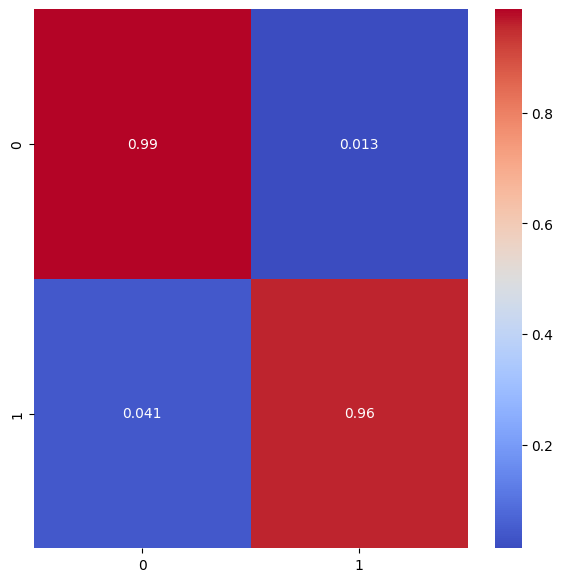

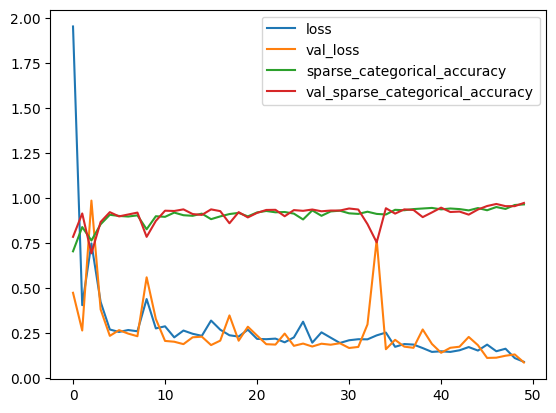

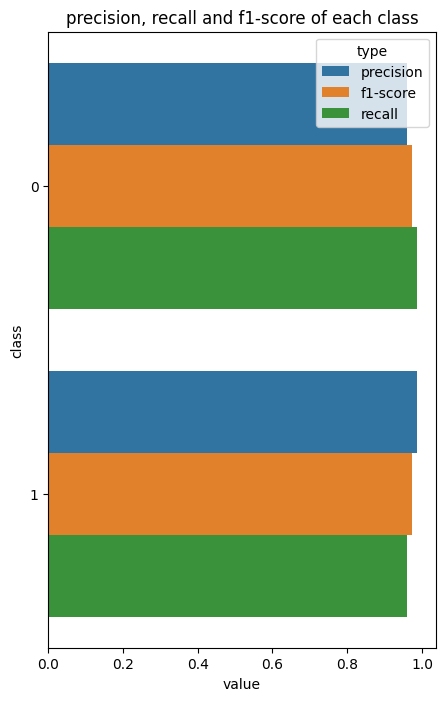

In [24]:
# for mlp
show_confusion_matrix(y_test, y_pred, "../imgs/mlp/eye/")
show_epoch_history(history, "../imgs/mlp/eye/")
evaluate_neural_network(y_test, y_pred, "../imgs/mlp/eye/")


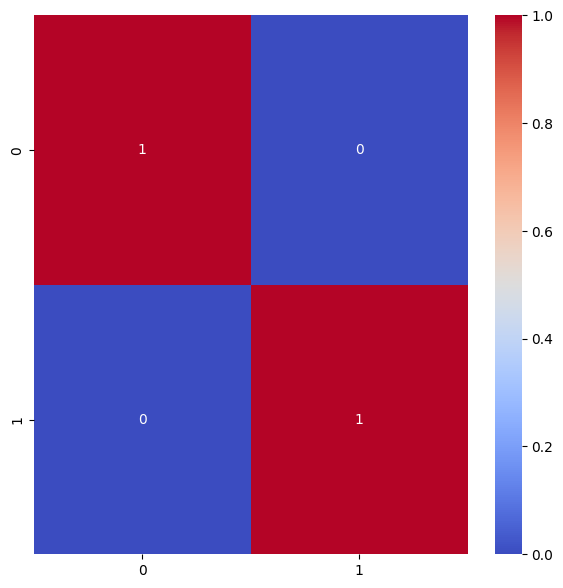

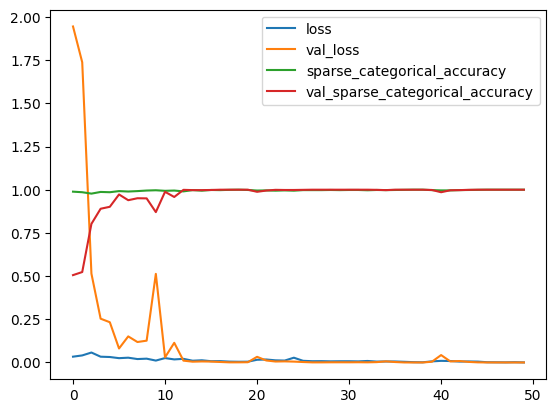

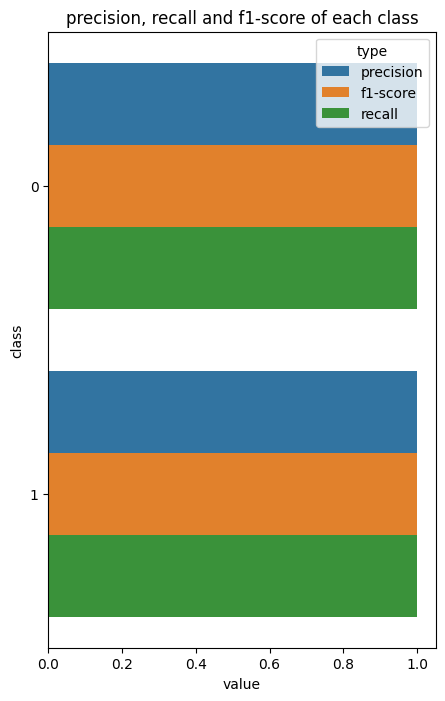

In [23]:
show_confusion_matrix(y_test_cnn, y_pred_cnn, "../imgs/cnn/eye/")
show_epoch_history(history_cnn, "../imgs/cnn/eye/")
evaluate_neural_network(y_test_cnn, y_pred_cnn, "../imgs/cnn/eye/")


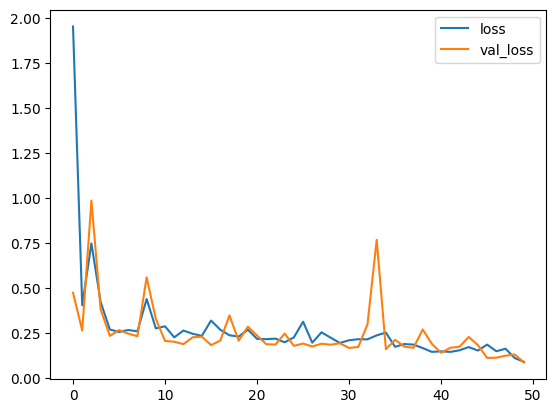

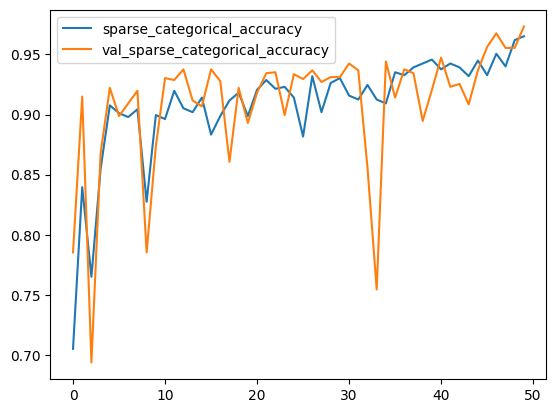

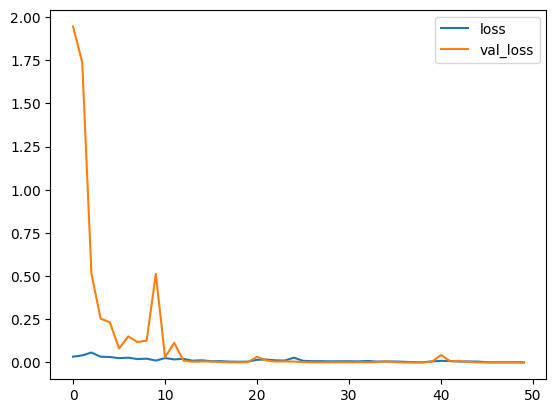

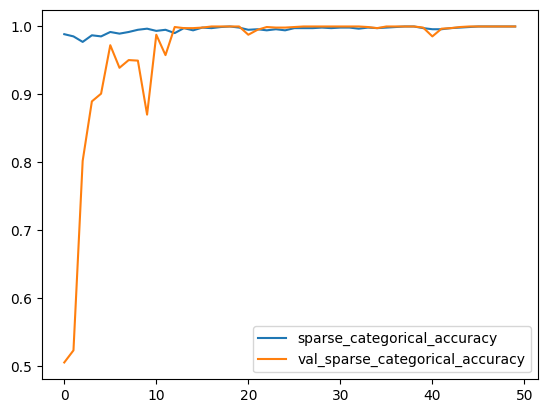

In [25]:


def show_epoch_history_separate(history, path="../imgs/cnn/eye/"):
    history_df = pd.DataFrame(history.history)

    plot = history_df.loc[:, ['loss', 'val_loss']].plot()
    fig1 = plot.get_figure()
    fig1.savefig(os.path.join(path, 'epoch_history_loss.svg'))

    plot2 = history_df.loc[:, ['sparse_categorical_accuracy', 'val_sparse_categorical_accuracy']].plot()
    fig2 = plot2.get_figure()
    fig2.savefig(os.path.join(path, 'epoch_history_accuracy.svg'))

show_epoch_history_separate(history, "../imgs/mlp/eye/")
show_epoch_history_separate(history_cnn)
